# Question 5: Capacity control and validation

We generate independent training, validation, and test observations from the specified logistic model.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit

rng = np.random.default_rng(2026)
d = 20
w_star = np.zeros(d)
w_star[:2] = 1

def generate_data(n):
    X = rng.normal(size=(n, d))
    probability = expit(X @ w_star)
    y = np.where(rng.random(n) < probability, 1, -1)
    return X, y

X_train, y_train = generate_data(300)
X_val, y_val = generate_data(1000)
X_test, y_test = generate_data(5000)

## (a) Constrained empirical risk minimization

For each radius, we minimize mean logistic loss using SciPy's SLSQP solver with `ftol=1e-10`. The constraint is $D^2-\|w\|_2^2\geq 0$.

In [12]:
radii = [0.1, 0.3, 1, 3, 10, 30]

def logistic_loss(w, X, y):
    return np.mean(np.logaddexp(0, -y * (X @ w)))

def logistic_gradient(w, X, y):
    return -(X.T @ (y * expit(-y * (X @ w)))) / len(y)

models = []
train_losses = []
val_losses = []

for D in radii:
    result = minimize(
        logistic_loss, np.zeros(d), args=(X_train, y_train),
        jac=logistic_gradient, method="SLSQP",
        constraints={"type": "ineq", "fun": lambda w: D**2 - w @ w,
                     "jac": lambda w: -2 * w},
        options={"ftol": 1e-10}
    )
    if not result.success or np.linalg.norm(result.x) > D + 1e-6:
        raise RuntimeError(f"Optimization failed for D={D}: {result.message}")
    models.append(result.x)
    train_losses.append(logistic_loss(result.x, X_train, y_train))
    val_losses.append(logistic_loss(result.x, X_val, y_val))
    print(f"D = {D:4g}  ||w|| = {np.linalg.norm(result.x):.6f}  "
          f"train = {train_losses[-1]:.6f}  validation = {val_losses[-1]:.6f}")
    largest = np.argsort(np.abs(result.x))[-5:][::-1]
    contribution = np.sum(np.abs(result.x[largest])) / np.sum(np.abs(result.x))
    print("Top 5 coefficients (index, value):", [(int(i), float(result.x[i])) for i in largest])
    print(f"Share of total absolute coefficient magnitude: {contribution:.2%}")

D =  0.1  ||w|| = 0.100000  train = 0.659165  validation = 0.670522
Top 5 coefficients (index, value): [(0, 0.06795453498164986), (1, 0.06353561870497192), (18, -0.02174929747215022), (14, 0.014616957669197532), (12, -0.014276363074532552)]
Share of total absolute coefficient magnitude: 73.27%
D =  0.3  ||w|| = 0.300000  train = 0.600439  validation = 0.632351
Top 5 coefficients (index, value): [(0, 0.20248500279291015), (1, 0.1931125428666776), (18, -0.06628328649473546), (14, 0.042301439884908316), (12, -0.04163957950492839)]
Share of total absolute coefficient magnitude: 73.57%
D =    1  ||w|| = 1.000000  train = 0.474066  validation = 0.563330
Top 5 coefficients (index, value): [(0, 0.661297316401122), (1, 0.6612602112805949), (18, -0.23060077649738375), (14, 0.12088193543433369), (12, -0.11799211538673984)]
Share of total absolute coefficient magnitude: 70.95%
D =    3  ||w|| = 2.312360  train = 0.415656  validation = 0.600462
Top 5 coefficients (index, value): [(1, 1.542105311063

## (b) Validation selection and test performance

The radii are in increasing order, so `argmin` selects the smaller radius if validation losses tie. The test set is evaluated only for the selected model.

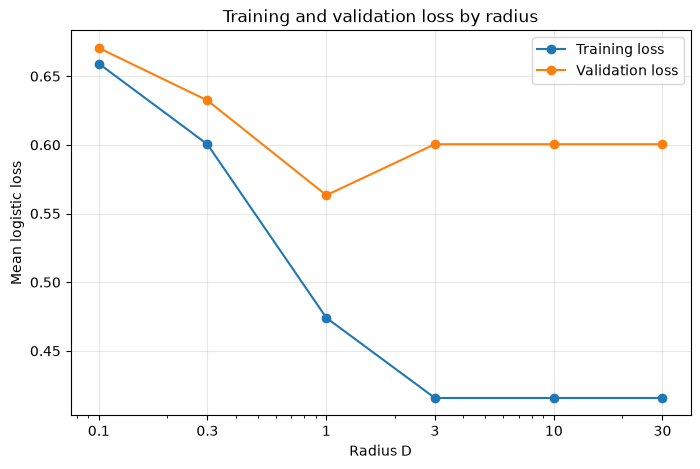

Selected D: 1
Test logistic loss: 0.564648
Test 0–1 error: 0.290800


In [13]:
plt.figure(figsize=(8, 5))
plt.plot(radii, train_losses, "o-", label="Training loss")
plt.plot(radii, val_losses, "o-", label="Validation loss")
plt.xscale("log")
plt.xticks(radii, radii)
plt.xlabel("Radius D")
plt.ylabel("Mean logistic loss")
plt.title("Training and validation loss by radius")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

selected = np.argmin(val_losses)
w_selected = models[selected]
test_loss = logistic_loss(w_selected, X_test, y_test)
test_error = np.mean(np.where(X_test @ w_selected >= 0, 1, -1) != y_test)
print(f"Selected D: {radii[selected]}")
print(f"Test logistic loss: {test_loss:.6f}")
print(f"Test 0–1 error: {test_error:.6f}")

## Effect of sample size for $D=3$

The true parameter has norm $\|w^*\|_2=\sqrt{2}$, which is inside the constraint ball. We generate a separate dataset with seed 2026 and use nested prefixes as training sets. Each fit uses only its training observations; the optimizer and tolerance are the same as above. The norms need not approach the true norm monotonically because of sampling variation.

n =   300  estimated norm = 1.541125  true norm = 1.414214
n =  1000  estimated norm = 1.394305  true norm = 1.414214
n =  3000  estimated norm = 1.407579  true norm = 1.414214
n = 10000  estimated norm = 1.388502  true norm = 1.414214
n = 100000  estimated norm = 1.405689  true norm = 1.414214
n = 1000000  estimated norm = 1.409875  true norm = 1.414214


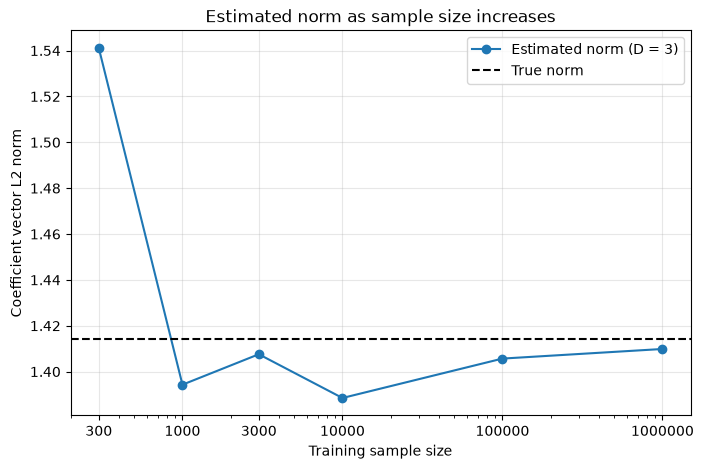

In [14]:
sample_sizes = [300, 1000, 3000, 10000, 100_000, 1_000_000]
rng_sizes = np.random.default_rng(2026)
X_sizes = rng_sizes.normal(size=(max(sample_sizes), d))
y_sizes = np.where(rng_sizes.random(max(sample_sizes)) < expit(X_sizes @ w_star), 1, -1)

norms = []
for n in sample_sizes:
    result = minimize(
        logistic_loss, np.zeros(d), args=(X_sizes[:n], y_sizes[:n]),
        jac=logistic_gradient, method="SLSQP",
        constraints={"type": "ineq", "fun": lambda w: 3**2 - w @ w,
                     "jac": lambda w: -2 * w},
        options={"ftol": 1e-10, "maxiter": 1000}
    )
    if not result.success or np.linalg.norm(result.x) > 3 + 1e-6:
        raise RuntimeError(f"Optimization failed for n={n}: {result.message}")
    norms.append(np.linalg.norm(result.x))
    print(f"n = {n:5d}  estimated norm = {norms[-1]:.6f}  "
          f"true norm = {np.linalg.norm(w_star):.6f}")

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, norms, "o-", label="Estimated norm (D = 3)")
plt.axhline(np.linalg.norm(w_star), color="black", linestyle="--", label="True norm")
plt.xscale("log")
plt.xticks(sample_sizes, sample_sizes)
plt.xlabel("Training sample size")
plt.ylabel("Coefficient vector L2 norm")
plt.title("Estimated norm as sample size increases")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Optional extension: $\ell_1$ constraint

We fit the same radius grid with $\|w\|_1\le D$ and select the radius by validation loss, as before. To use smooth constraints with SLSQP, write $w=u-v$ with $u,v\geq 0$ and $\sum_j(u_j+v_j)\le D$. This is exactly equivalent to the $\ell_1$ constraint. The solver and tolerance are the same as in part (a).

In [5]:
l1_models = []
l1_train_losses = []
l1_val_losses = []

for D in radii:
    result = minimize(
        lambda z: logistic_loss(z[:d] - z[d:], X_train, y_train),
        np.zeros(2 * d),
        jac=lambda z: np.concatenate((logistic_gradient(z[:d] - z[d:], X_train, y_train),
                                      -logistic_gradient(z[:d] - z[d:], X_train, y_train))),
        method="SLSQP", bounds=[(0, None)] * (2 * d),
        constraints={"type": "ineq", "fun": lambda z: D - np.sum(z),
                     "jac": lambda z: -np.ones(2 * d)},
        options={"ftol": 1e-10, "maxiter": 1000}
    )
    w = result.x[:d] - result.x[d:]
    if not result.success or np.linalg.norm(w, 1) > D + 1e-6:
        raise RuntimeError(f"L1 optimization failed for D={D}: {result.message}")
    l1_models.append(w)
    l1_train_losses.append(logistic_loss(w, X_train, y_train))
    l1_val_losses.append(logistic_loss(w, X_val, y_val))
    print(f"D = {D:4g}  ||w||_1 = {np.linalg.norm(w, 1):.6f}  "
          f"train = {l1_train_losses[-1]:.6f}  validation = {l1_val_losses[-1]:.6f}")

l1_selected = np.argmin(l1_val_losses)
w_l1 = l1_models[l1_selected]
print(f"\nSelected L1 radius: {radii[l1_selected]}")
print(f"Selected L2 radius: {radii[selected]}")
print("Feature       true         L1         L2")
for i in range(d):
    print(f"{i:7d}  {w_star[i]:9.4f}  {w_l1[i]:9.4f}  {w_selected[i]:9.4f}")
print(f"\nNonzero coefficients (|w| > 1e-6): "
      f"L1 = {np.sum(np.abs(w_l1) > 1e-6)}, L2 = {np.sum(np.abs(w_selected) > 1e-6)}")

D =  0.1  ||w||_1 = 0.100000  train = 0.670266  validation = 0.675912
D =  0.3  ||w||_1 = 0.300000  train = 0.629476  validation = 0.644789
D =    1  ||w||_1 = 1.000000  train = 0.528158  validation = 0.569972
D =    3  ||w||_1 = 3.000000  train = 0.436970  validation = 0.546827
D =   10  ||w||_1 = 6.023657  train = 0.415656  validation = 0.600462
D =   30  ||w||_1 = 6.023657  train = 0.415656  validation = 0.600462

Selected L1 radius: 3
Selected L2 radius: 1
Feature       true         L1         L2
      0     1.0000     1.1495     0.6613
      1     1.0000     1.1440     0.6613
      2     0.0000    -0.0619    -0.0820
      3     0.0000     0.0000     0.0393
      4     0.0000    -0.0000     0.0653
      5     0.0000     0.0477     0.0719
      6     0.0000     0.0000    -0.0326
      7     0.0000     0.0000     0.0481
      8     0.0000     0.0000     0.0340
      9     0.0000     0.0000     0.0188
     10     0.0000     0.0000    -0.0296
     11     0.0000     0.0713     0.0664
  